# Resultados dos seis experimentos controlados

Este notebook reconstrói as tabelas e figuras a partir dos **modelos, históricos e previsões reais**. A execução não treina modelos. A seleção do modelo é congelada em `artifacts/selection.json` pelo maior **F1 macro de validação**; em caso de empate, usa menor perda de validação e, depois, o ID. O teste só é aberto após essa seleção.

**Execução:** instale `requirements.txt`, mantenha os arquivos de dados e os seis diretórios de `artifacts/runs/`, e execute todas as células. Para recalcular previsões diretamente dos checkpoints sem novo treinamento, execute na raiz `python -m src.evaluate --root .`; em seguida, execute este notebook. Para apenas regenerar figuras e tabelas: `python -m src.reporting --root .`.

As verificações automáticas conferem os caminhos e rótulos do teste, probabilidades, argmax, matrizes e métricas. Ausência de um experimento ou divergência de evidências interrompe a execução; nenhum valor é preenchido artificialmente.


In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image, Markdown

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "src/reporting.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Abra o notebook dentro da pasta trashnet ou notebooks/.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
pd.set_option("display.max_rows", 60)
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)
from src.reporting import CLASSES, RUNS, LABELS, generate_eda, generate_report
print("Raiz do projeto:", ROOT)


Raiz do projeto: /home/joao/Documents/Codex/2026-10-21/fala-chat-em-resumo-fa-o/work/review/clean/trashnet


In [2]:
report = generate_report(ROOT)
summary = report["summary"].set_index("run_id").loc[RUNS]
classwise = report["classwise"]
selection = report["selection"]
selected = selection["selected_run"]
display(Markdown(f"**Modelo selecionado pela validação:** {LABELS[selected]}. **Seleção congelada em:** `{selection['frozen_at_utc']}`."))
display(pd.DataFrame(selection["candidates"]).drop(columns=["checkpoint_sha256"], errors="ignore"))
print("Critério:", selection["criterion"], "| Desempate:", selection["tie_break"])


Critério: val_macro_f1 | Desempate: lowest_val_loss_then_id


**Modelo selecionado pela validação:** CNN 128 × 96 · sem pesos. **Seleção congelada em:** `2026-10-22T11:30:34.999857+00:00`.

,id,val_macro_f1,val_loss,val_accuracy,best_epoch
0,mlp_128,0.3828,1.4995,0.4565,23
1,mlp_128_weighted,0.3335,1.6397,0.3879,8
2,cnn_128,0.6333,0.9540,0.6702,10
3,cnn_128_weighted,0.6192,1.0841,0.6253,8
4,cnn_256,0.5736,0.9350,0.6596,10
5,cnn_512,0.4719,1.0830,0.5805,11


## Busca preliminar da taxa da MLP
A MLP inicial, com Adam 0,001, praticamente colapsou para uma classe na validação. Antes de abrir o teste, investigaram-se 0,0001 e 0,0003 apenas na MLP sem pesos, com o restante do protocolo fixo. A maior F1 macro de validação definiu a taxa dos dois treinamentos MLP finais, reiniciados do zero. Os pilotos são separados dos seis experimentos controlados. As CNNs mantêm 0,001; portanto, a comparação entre arquiteturas se refere a sistemas com taxas distintas escolhidas por esse procedimento, e não isola somente a estrutura da rede.


In [3]:
search_path = ROOT / "artifacts/search/search_summary.csv"
if search_path.exists():
    display(pd.read_csv(search_path).sort_values("learning_rate"))
    display(Markdown("**Decisão registrada:** " + json.dumps(json.loads((ROOT / "artifacts/search/decision.json").read_text()), ensure_ascii=False)))
configs = [report["evidence"][r]["config"] for r in RUNS]
display(pd.DataFrame(configs)[["id", "learning_rate", "batch_size", "weighted", "seed", "max_epochs", "patience"]])


,id,learning_rate,val_macro_f1,val_accuracy,val_loss,best_epoch,epochs_trained,train_seconds
1,mlp_lr_0p0001,0.0001,0.3828,0.4565,1.4995,23,30,79.4209
2,mlp_lr_0p0003,0.0003,0.1277,0.2850,1.7028,3,10,24.5825
0,baseline_mlp_0p0010,0.0010,0.0634,0.2348,1.7264,1,8,16.4583


**Decisão registrada:** {"completed_at_utc": "2026-10-22T11:28:17.578792+00:00", "selected_learning_rate": 0.0001, "criterion": "highest validation macro F1 of unweighted MLP; ties lowest validation loss then id", "test_used": false, "rates": [0.001, 0.0001, 0.0003], "reason": "Initial MLP predicted almost a single class on validation. Two smaller Adam learning rates were investigated before test access.", "final_training": "Both MLP experiments restarted from seed 42 with selected learning rate; CNN protocol unchanged."}

,id,learning_rate,batch_size,weighted,seed,max_epochs,patience
0,mlp_128,0.0001,32,False,42,30,7
1,mlp_128_weighted,0.0001,32,True,42,30,7
2,cnn_128,0.0010,32,False,42,30,7
3,cnn_128_weighted,0.0010,32,True,42,30,7
4,cnn_256,0.0010,32,False,42,30,7
5,cnn_512,0.0010,32,False,42,30,7


## Distribuição, exemplos e integridade

A análise completa está no notebook exploratório. Aqui se repetem as figuras exigidas para permitir a leitura independente dos resultados. Há duplicatas com rótulos conflitantes no conjunto original; a divisão mantém cada grupo de pixels idênticos dentro de uma única partição. Isso evita vazamento exato, mas preserva o ruído de rótulos documentado.


Duplicatas de pixels entre conjuntos: 0


split,train,val,test
class_name,,,
glass,350,75,76
paper,416,89,89
cardboard,282,61,60
plastic,337,72,73
metal,287,61,62
trash,96,21,20


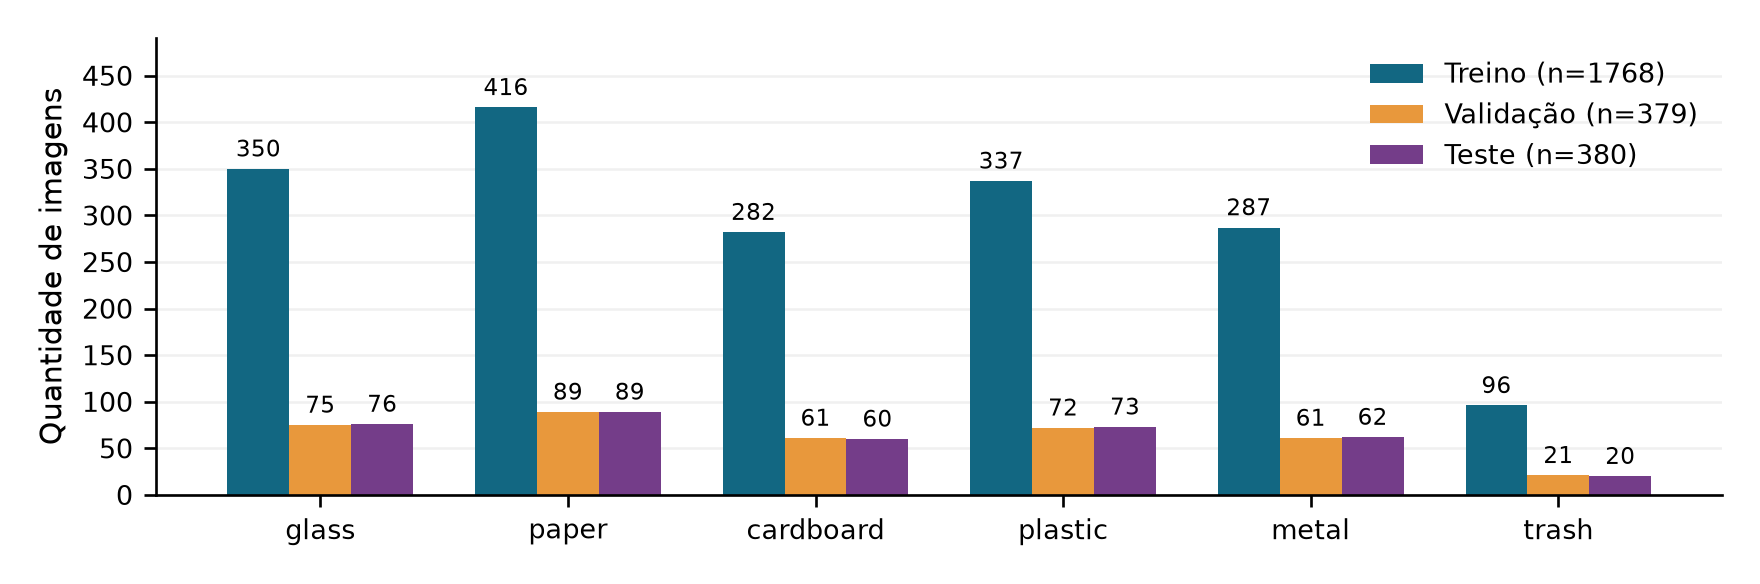

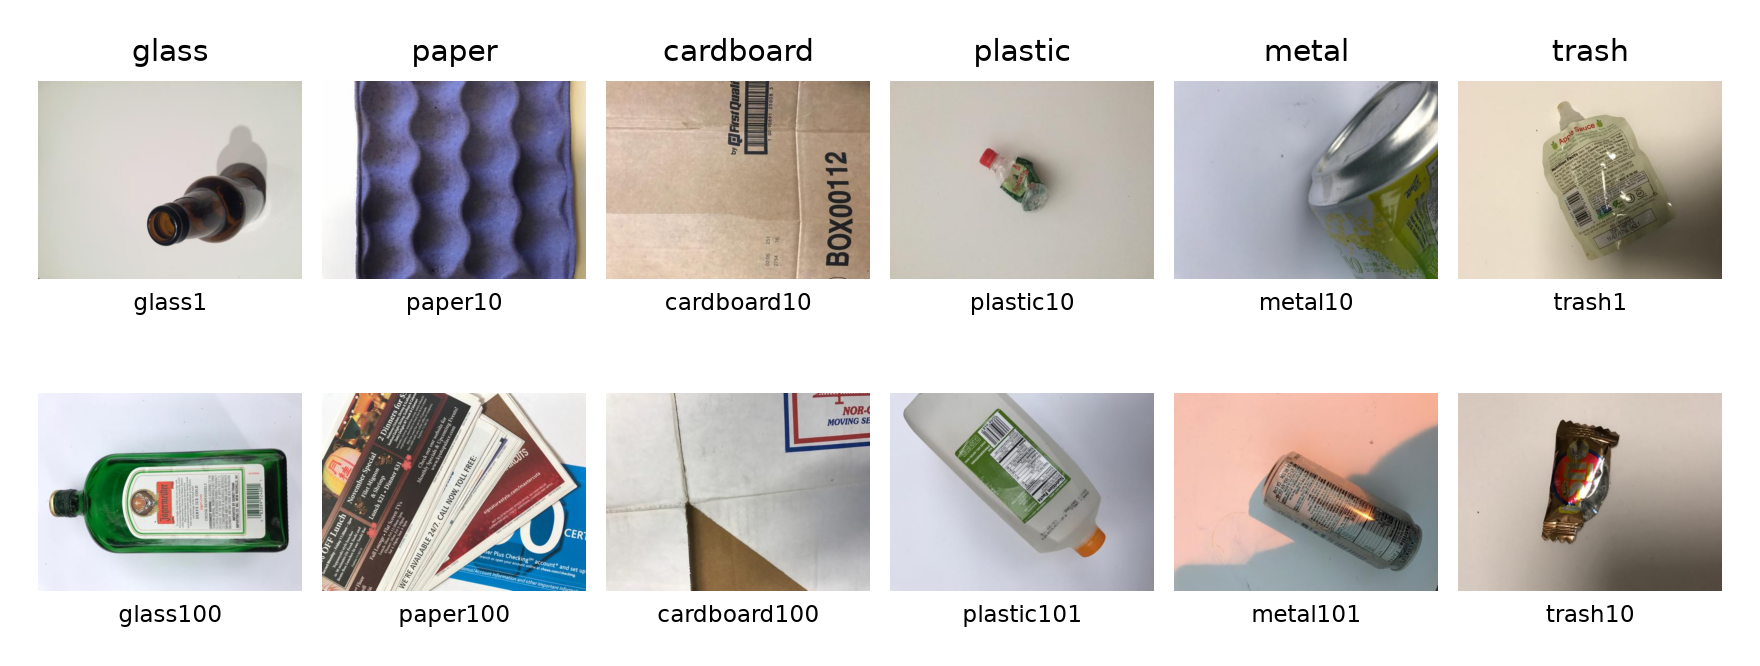

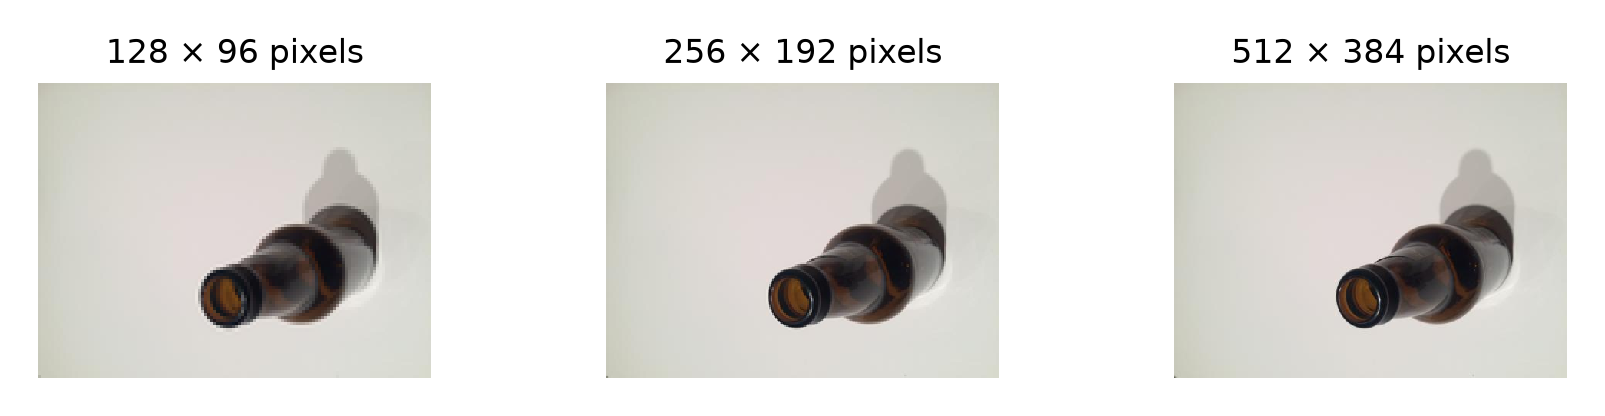

In [4]:
display(report["distribution"])
for name in ["class_distribution", "class_examples", "resolution_examples"]:
    display(Image(filename=str(ROOT / f"artifacts/figures/{name}.png")))
print("Duplicatas de pixels entre conjuntos:", report["audit"].get("cross_split_pixel_duplicates"))


## Desempenho e custo computacional

Acurácia, precisão, recall e F1 são apresentados entre 0 e 1 nas tabelas; os gráficos usam percentuais. F1 macro é a média simples dos F1 das seis classes. `support` é a quantidade de imagens reais de cada classe, não a quantidade de previsões. Nas métricas de classe, `zero_division=0` atribui zero às razões indefinidas; a ausência de previsões para uma classe deve ser lida como falha do modelo para essa categoria.

O tempo total soma as épocas efetivamente treinadas; cada época inclui treino e validação. Download e preparação dos caches ficam fora da medição. O tempo médio divide o total pelo número de épocas. O tamanho corresponde ao arquivo `best.pt`. O RSS mede a memória do processo, incluindo biblioteca, modelo, otimizador e dados carregados; não é uma medida isolada da memória da rede. Os detalhes do hardware e da medição são exibidos abaixo a partir dos registros.


In [5]:
display(summary[["val_accuracy", "val_macro_f1", "test_accuracy", "test_macro_f1"]])
display(report["costs"].set_index("run_id")[["parameters", "model_size_mib", "epochs_trained", "best_epoch", "train_minutes", "mean_epoch_seconds", "peak_rss_mb", "batch_size"]])
for run_id in RUNS:
    m = report["evidence"][run_id]["metrics"]
    display(Markdown(f"**{run_id}:** hardware `{m['hardware']}`; tempo: {m.get('timing_method', 'ver config.json')}; memória: {m.get('memory_method', 'ver config.json')}."))


,val_accuracy,val_macro_f1,test_accuracy,test_macro_f1
run_id,,,,
mlp_128,0.4565,0.3828,0.4289,0.3543
mlp_128_weighted,0.3879,0.3335,0.3632,0.3028
cnn_128,0.6702,0.6333,0.6263,0.5944
cnn_128_weighted,0.6253,0.6192,0.5105,0.4997
cnn_256,0.6596,0.5736,0.6158,0.5609
cnn_512,0.5805,0.4719,0.5684,0.4496


,parameters,model_size_mib,epochs_trained,best_epoch,train_minutes,mean_epoch_seconds,peak_rss_mb,batch_size
run_id,,,,,,,,
mlp_128,4727366,18.0376,30,23,1.3818,2.7635,645.0781,32
mlp_128_weighted,4727366,18.0376,15,8,0.6171,2.4684,643.3984,32
cnn_128,24198,0.1015,17,10,0.8048,2.8404,572.8516,32
cnn_128_weighted,24198,0.1015,15,8,0.5434,2.1737,571.8516,32
cnn_256,24198,0.1015,17,10,2.1217,7.4882,969.2344,32
cnn_512,24198,0.1015,18,11,12.5999,41.9997,2305.3438,32


**mlp_128:** hardware `{'cpu': '11th Gen Intel(R) Core(TM) i3-1125G4 @ 2.00GHz', 'physical_cores': 4, 'logical_cpus': 8, 'ram_total_gib': 14.765, 'platform': 'Linux-7.0.0-38-generic-x86_64-with-glibc2.43', 'python': '3.14.4', 'torch': '2.14.1+cpu', 'numpy': '2.5.4', 'device': 'cpu', 'torch_threads': 4}`; tempo: sum of perf_counter epoch durations: training and validation; excludes setup, checkpoint I/O and final prediction export; memória: process RSS sampled every 100 ms throughout the epoch loop including checkpoint I/O; MiB; includes interpreter and mapped cache pages; no workers; CLI isolates each experiment in a process.

**mlp_128_weighted:** hardware `{'cpu': '11th Gen Intel(R) Core(TM) i3-1125G4 @ 2.00GHz', 'physical_cores': 4, 'logical_cpus': 8, 'ram_total_gib': 14.765, 'platform': 'Linux-7.0.0-38-generic-x86_64-with-glibc2.43', 'python': '3.14.4', 'torch': '2.14.1+cpu', 'numpy': '2.5.4', 'device': 'cpu', 'torch_threads': 4}`; tempo: sum of perf_counter epoch durations: training and validation; excludes setup, checkpoint I/O and final prediction export; memória: process RSS sampled every 100 ms throughout the epoch loop including checkpoint I/O; MiB; includes interpreter and mapped cache pages; no workers; CLI isolates each experiment in a process.

**cnn_128:** hardware `{'cpu': '11th Gen Intel(R) Core(TM) i3-1125G4 @ 2.00GHz', 'physical_cores': 4, 'logical_cpus': 8, 'ram_total_gib': 14.765, 'platform': 'Linux-7.0.0-38-generic-x86_64-with-glibc2.43', 'python': '3.14.4', 'torch': '2.14.1+cpu', 'numpy': '2.5.4', 'device': 'cpu', 'torch_threads': 4}`; tempo: sum of perf_counter epoch durations: training and validation; excludes setup, checkpoint I/O and final prediction export; memória: process RSS sampled every 100 ms throughout the epoch loop including checkpoint I/O; MiB; includes interpreter and mapped cache pages; no workers; CLI isolates each experiment in a process.

**cnn_128_weighted:** hardware `{'cpu': '11th Gen Intel(R) Core(TM) i3-1125G4 @ 2.00GHz', 'physical_cores': 4, 'logical_cpus': 8, 'ram_total_gib': 14.765, 'platform': 'Linux-7.0.0-38-generic-x86_64-with-glibc2.43', 'python': '3.14.4', 'torch': '2.14.1+cpu', 'numpy': '2.5.4', 'device': 'cpu', 'torch_threads': 4}`; tempo: sum of perf_counter epoch durations: training and validation; excludes setup, checkpoint I/O and final prediction export; memória: process RSS sampled every 100 ms throughout the epoch loop including checkpoint I/O; MiB; includes interpreter and mapped cache pages; no workers; CLI isolates each experiment in a process.

**cnn_256:** hardware `{'cpu': '11th Gen Intel(R) Core(TM) i3-1125G4 @ 2.00GHz', 'physical_cores': 4, 'logical_cpus': 8, 'ram_total_gib': 14.765, 'platform': 'Linux-7.0.0-38-generic-x86_64-with-glibc2.43', 'python': '3.14.4', 'torch': '2.14.1+cpu', 'numpy': '2.5.4', 'device': 'cpu', 'torch_threads': 4}`; tempo: sum of perf_counter epoch durations: training and validation; excludes setup, checkpoint I/O and final prediction export; memória: process RSS sampled every 100 ms throughout the epoch loop including checkpoint I/O; MiB; includes interpreter and mapped cache pages; no workers; CLI isolates each experiment in a process.

**cnn_512:** hardware `{'cpu': '11th Gen Intel(R) Core(TM) i3-1125G4 @ 2.00GHz', 'physical_cores': 4, 'logical_cpus': 8, 'ram_total_gib': 14.765, 'platform': 'Linux-7.0.0-38-generic-x86_64-with-glibc2.43', 'python': '3.14.4', 'torch': '2.14.1+cpu', 'numpy': '2.5.4', 'device': 'cpu', 'torch_threads': 4}`; tempo: sum of perf_counter epoch durations: training and validation; excludes setup, checkpoint I/O and final prediction export; memória: process RSS sampled every 100 ms throughout the epoch loop including checkpoint I/O; MiB; includes interpreter and mapped cache pages; no workers; CLI isolates each experiment in a process.

## Precisão, recall, F1 e suporte por classe

A ordem de classes é fixa: `glass`, `paper`, `cardboard`, `plastic`, `metal`, `trash`. Os seis relatórios são calculados no mesmo teste; diferenças de suporte entre modelos seriam erro de protocolo.


In [6]:
for run_id in RUNS:
    display(Markdown(f"### {LABELS[run_id]}"))
    display(classwise[classwise["run_id"] == run_id].drop(columns="run_id").set_index("class_name"))
    matrix = report["evidence"][run_id]["matrix"]
    absent = [CLASSES[i] for i, n in enumerate(matrix.sum(axis=0)) if n == 0]
    if absent:
        display(Markdown("Classes sem nenhuma previsão (precisão definida como zero): **" + ", ".join(absent) + "**."))
assert classwise.groupby("class_name")["support"].nunique().eq(1).all()


### MLP 128 × 96 · sem pesos

,precision,recall,f1,support
class_name,,,,
glass,0.3182,0.3684,0.3415,76
paper,0.3750,0.6404,0.4730,89
cardboard,0.8222,0.6167,0.7048,60
plastic,0.4737,0.4932,0.4832,73
metal,0.2632,0.0806,0.1235,62
trash,0.0000,0.0000,0.0000,20


Classes sem nenhuma previsão (precisão definida como zero): **trash**.

### MLP 128 × 96 · com pesos

,precision,recall,f1,support
class_name,,,,
glass,0.0000,0.0000,0.0000,76
paper,0.4627,0.3483,0.3974,89
cardboard,0.4211,0.6667,0.5161,60
plastic,0.3248,0.6986,0.4435,73
metal,0.3077,0.0645,0.1067,62
trash,0.2500,0.6000,0.3529,20


...

### CNN 256 × 192 · sem pesos

,precision,recall,f1,support
class_name,,,,
glass,0.4744,0.4868,0.4805,76
paper,0.6031,0.8876,0.7182,89
cardboard,0.9545,0.7000,0.8077,60
plastic,0.6429,0.7397,0.6879,73
metal,0.4865,0.2903,0.3636,62
trash,0.6667,0.2000,0.3077,20


### CNN 512 × 384 · sem pesos

,precision,recall,f1,support
class_name,,,,
glass,0.4946,0.6053,0.5444,76
paper,0.5797,0.8989,0.7048,89
cardboard,0.5400,0.9000,0.6750,60
plastic,0.7097,0.3014,0.4231,73
metal,0.7778,0.2258,0.3500,62
trash,0.0000,0.0000,0.0000,20


Classes sem nenhuma previsão (precisão definida como zero): **trash**.

## Curvas de aprendizagem e checkpoint

Linhas azuis representam treino; laranjas, validação; a linha vertical pontilhada indica a época dos pesos salvos. Nos experimentos ponderados, **a perda de treino usa pesos e a de validação não**: as magnitudes não são diretamente comparáveis. A acurácia de treino é acumulada durante as atualizações, com dropout ativo; a validação ocorre após a época, em modo de avaliação. Portanto, um desnível isolado entre curvas não prova sobreajuste. A leitura considera tendências, evolução da validação e o checkpoint recuperado.


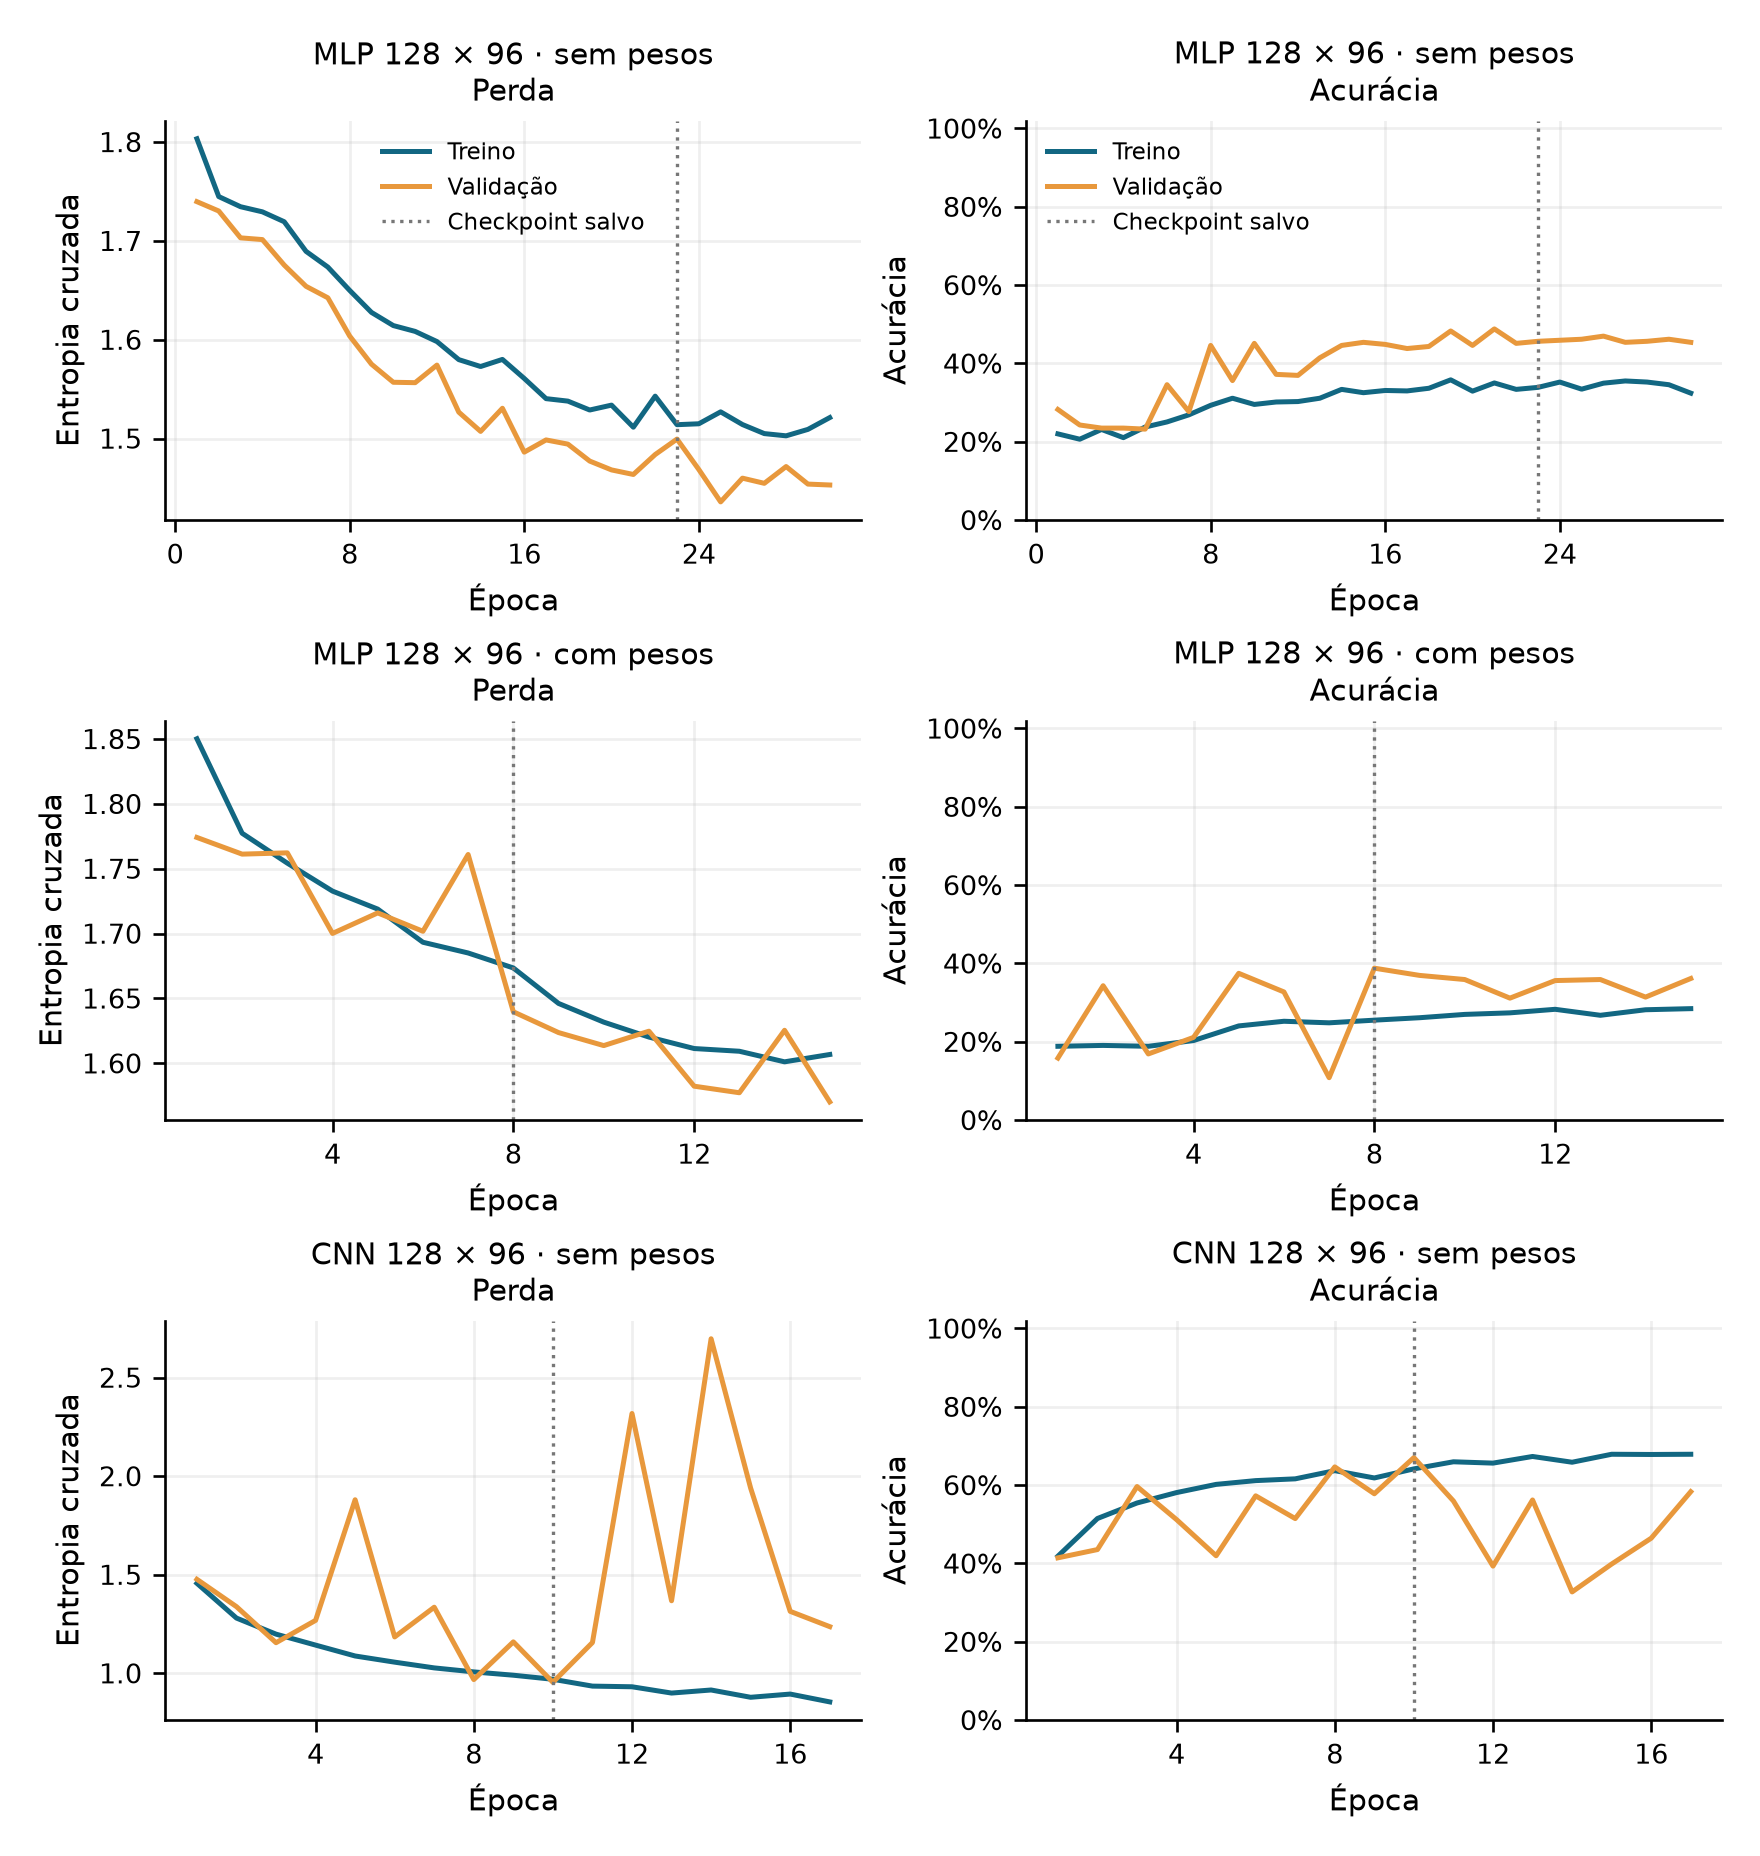

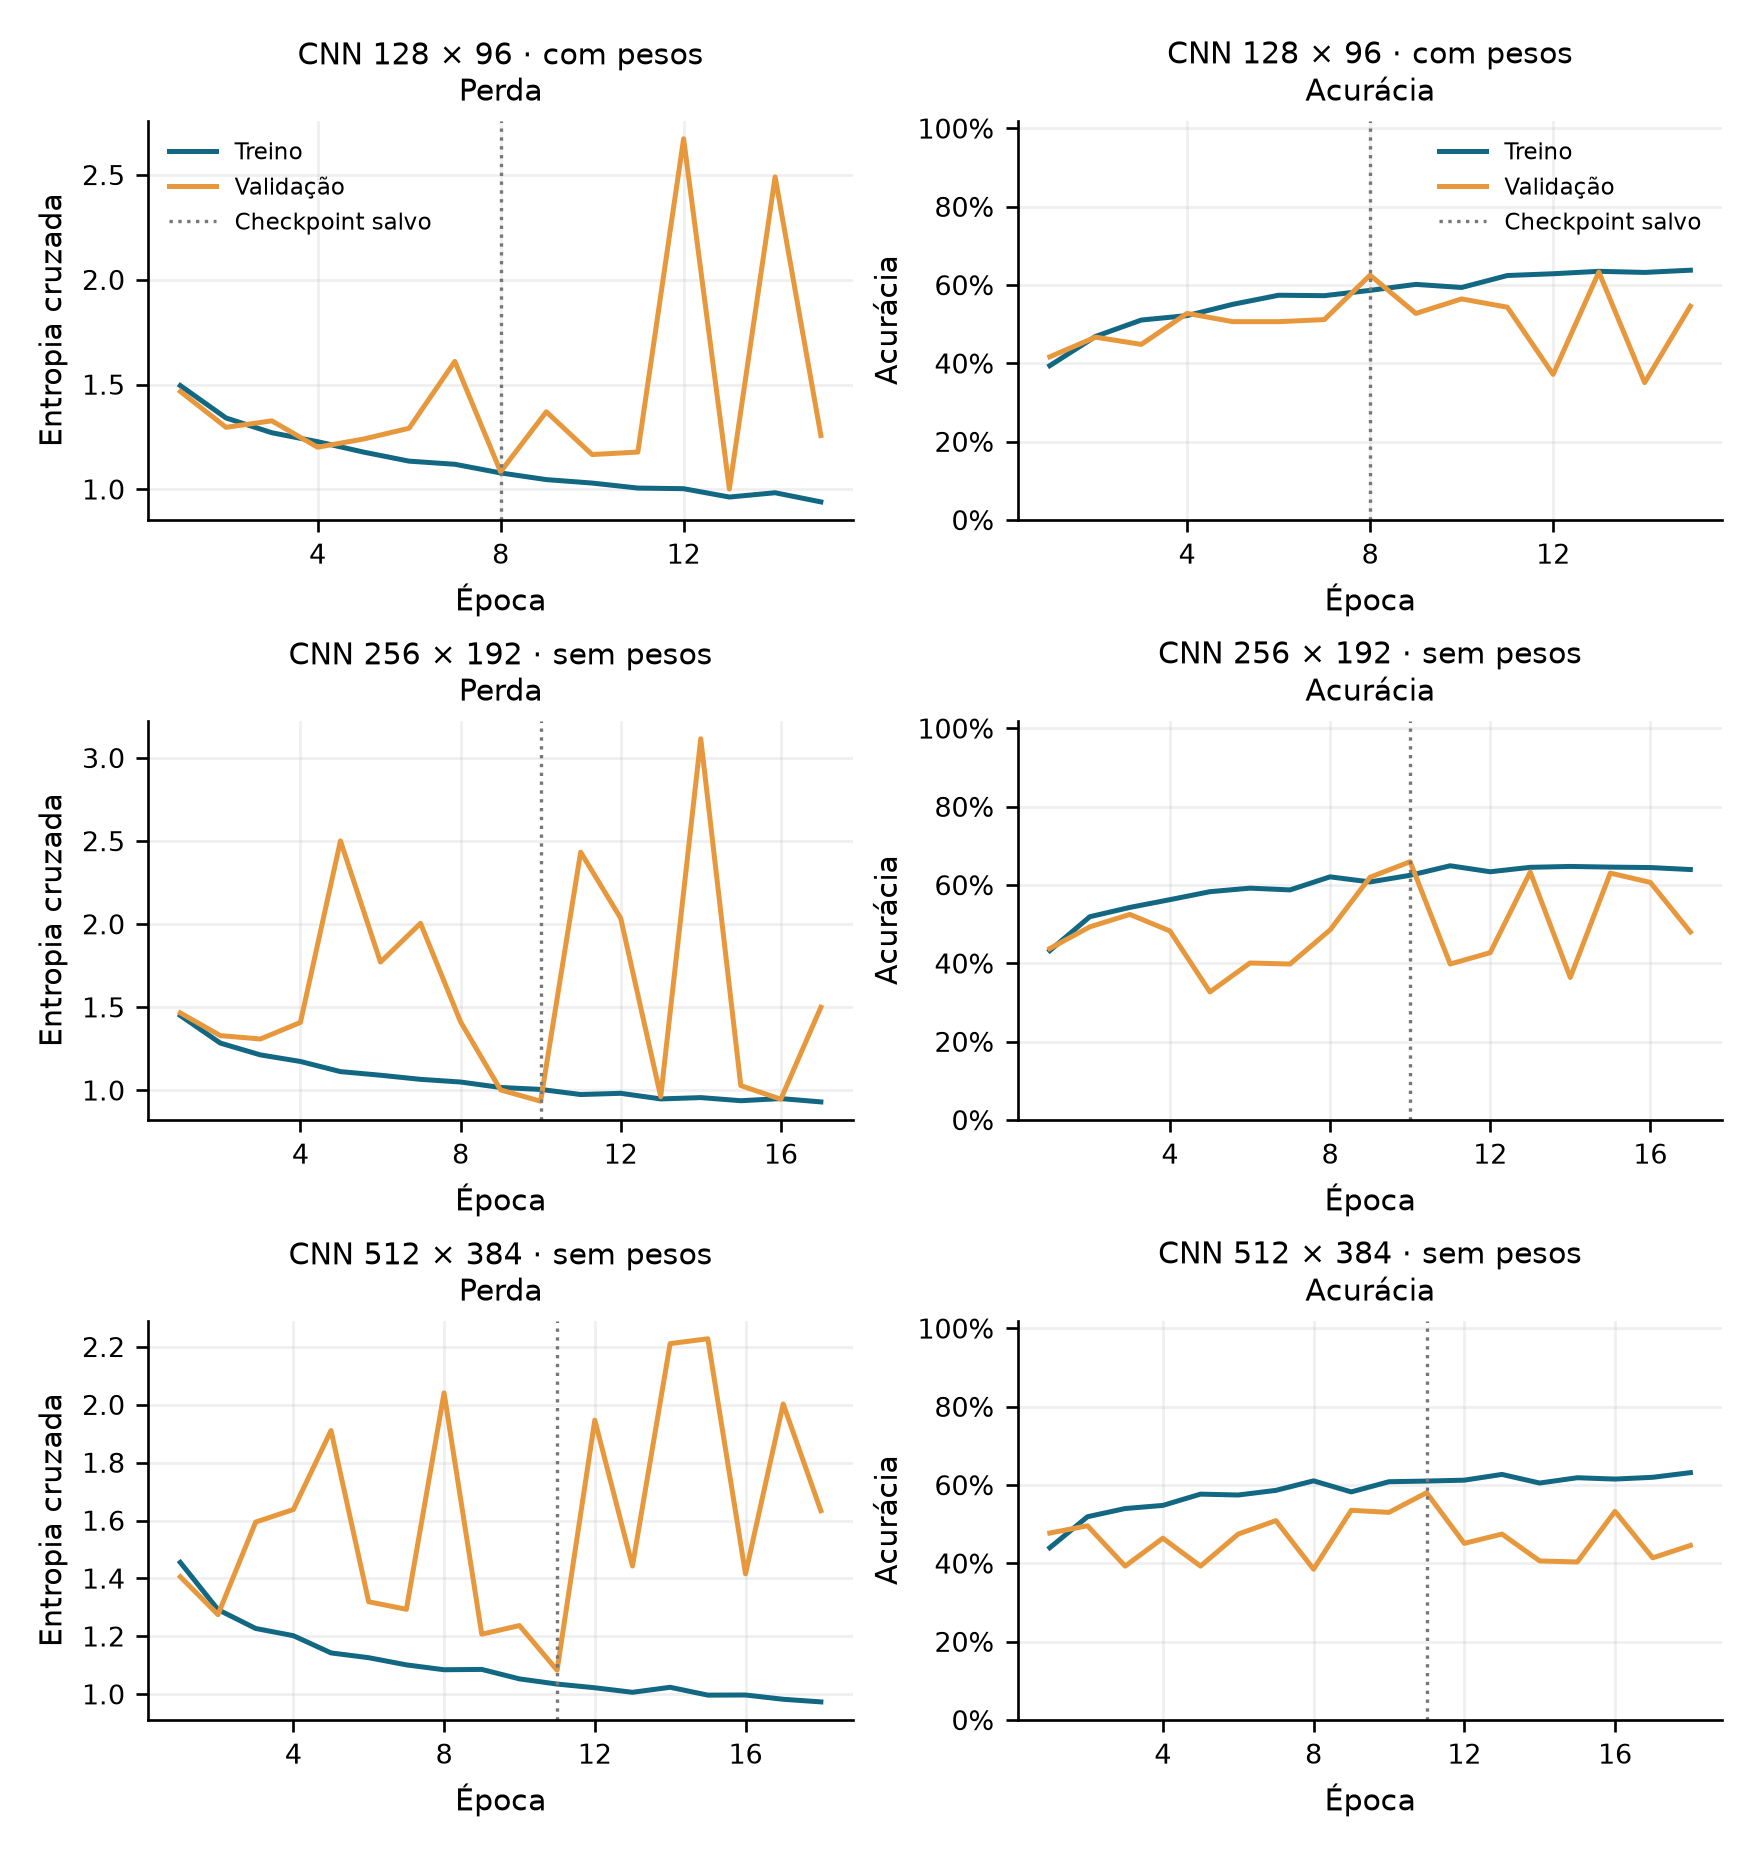

,época_salva,épocas_executadas,F1_val_salvo,F1_val_última,acc_treino_época_salva,acc_val_época_salva,parada
modelo,,,,,,,
mlp_128,23,30,0.3828,0.3257,0.3388,0.4565,early_stopping
mlp_128_weighted,8,15,0.3335,0.3162,0.2551,0.3879,early_stopping
cnn_128,10,17,0.6333,0.4789,0.6414,0.6702,early_stopping
cnn_128_weighted,8,15,0.6192,0.4792,0.5865,0.6253,early_stopping
cnn_256,10,17,0.5736,0.4480,0.6250,0.6596,early_stopping
cnn_512,11,18,0.4719,0.3608,0.6103,0.5805,early_stopping


In [7]:
for name in ["learning_curves_1", "learning_curves_2"]:
    display(Image(filename=str(ROOT / f"artifacts/figures/{name}.png")))
curve_rows = []
for run_id in RUNS:
    run = report["evidence"][run_id]
    h = run["history"]
    best = h.loc[h["epoch"] == run["metrics"]["best_epoch"]].iloc[0]
    curve_rows.append({"modelo": run_id, "época_salva": int(best["epoch"]), "épocas_executadas": len(h), "F1_val_salvo": best["val_macro_f1"], "F1_val_última": h.iloc[-1]["val_macro_f1"], "acc_treino_época_salva": best["train_accuracy"], "acc_val_época_salva": best["val_accuracy"], "parada": run["metrics"].get("stopping_reason")})
display(pd.DataFrame(curve_rows).set_index("modelo"))


## Matrizes de confusão

As linhas são as classes reais e as colunas as classes previstas. Cada célula mostra **contagem e porcentagem da linha**. A normalização por linha facilita comparar classes com suportes distintos. Os valores percentuais podem não somar exatamente 100% por arredondamento.


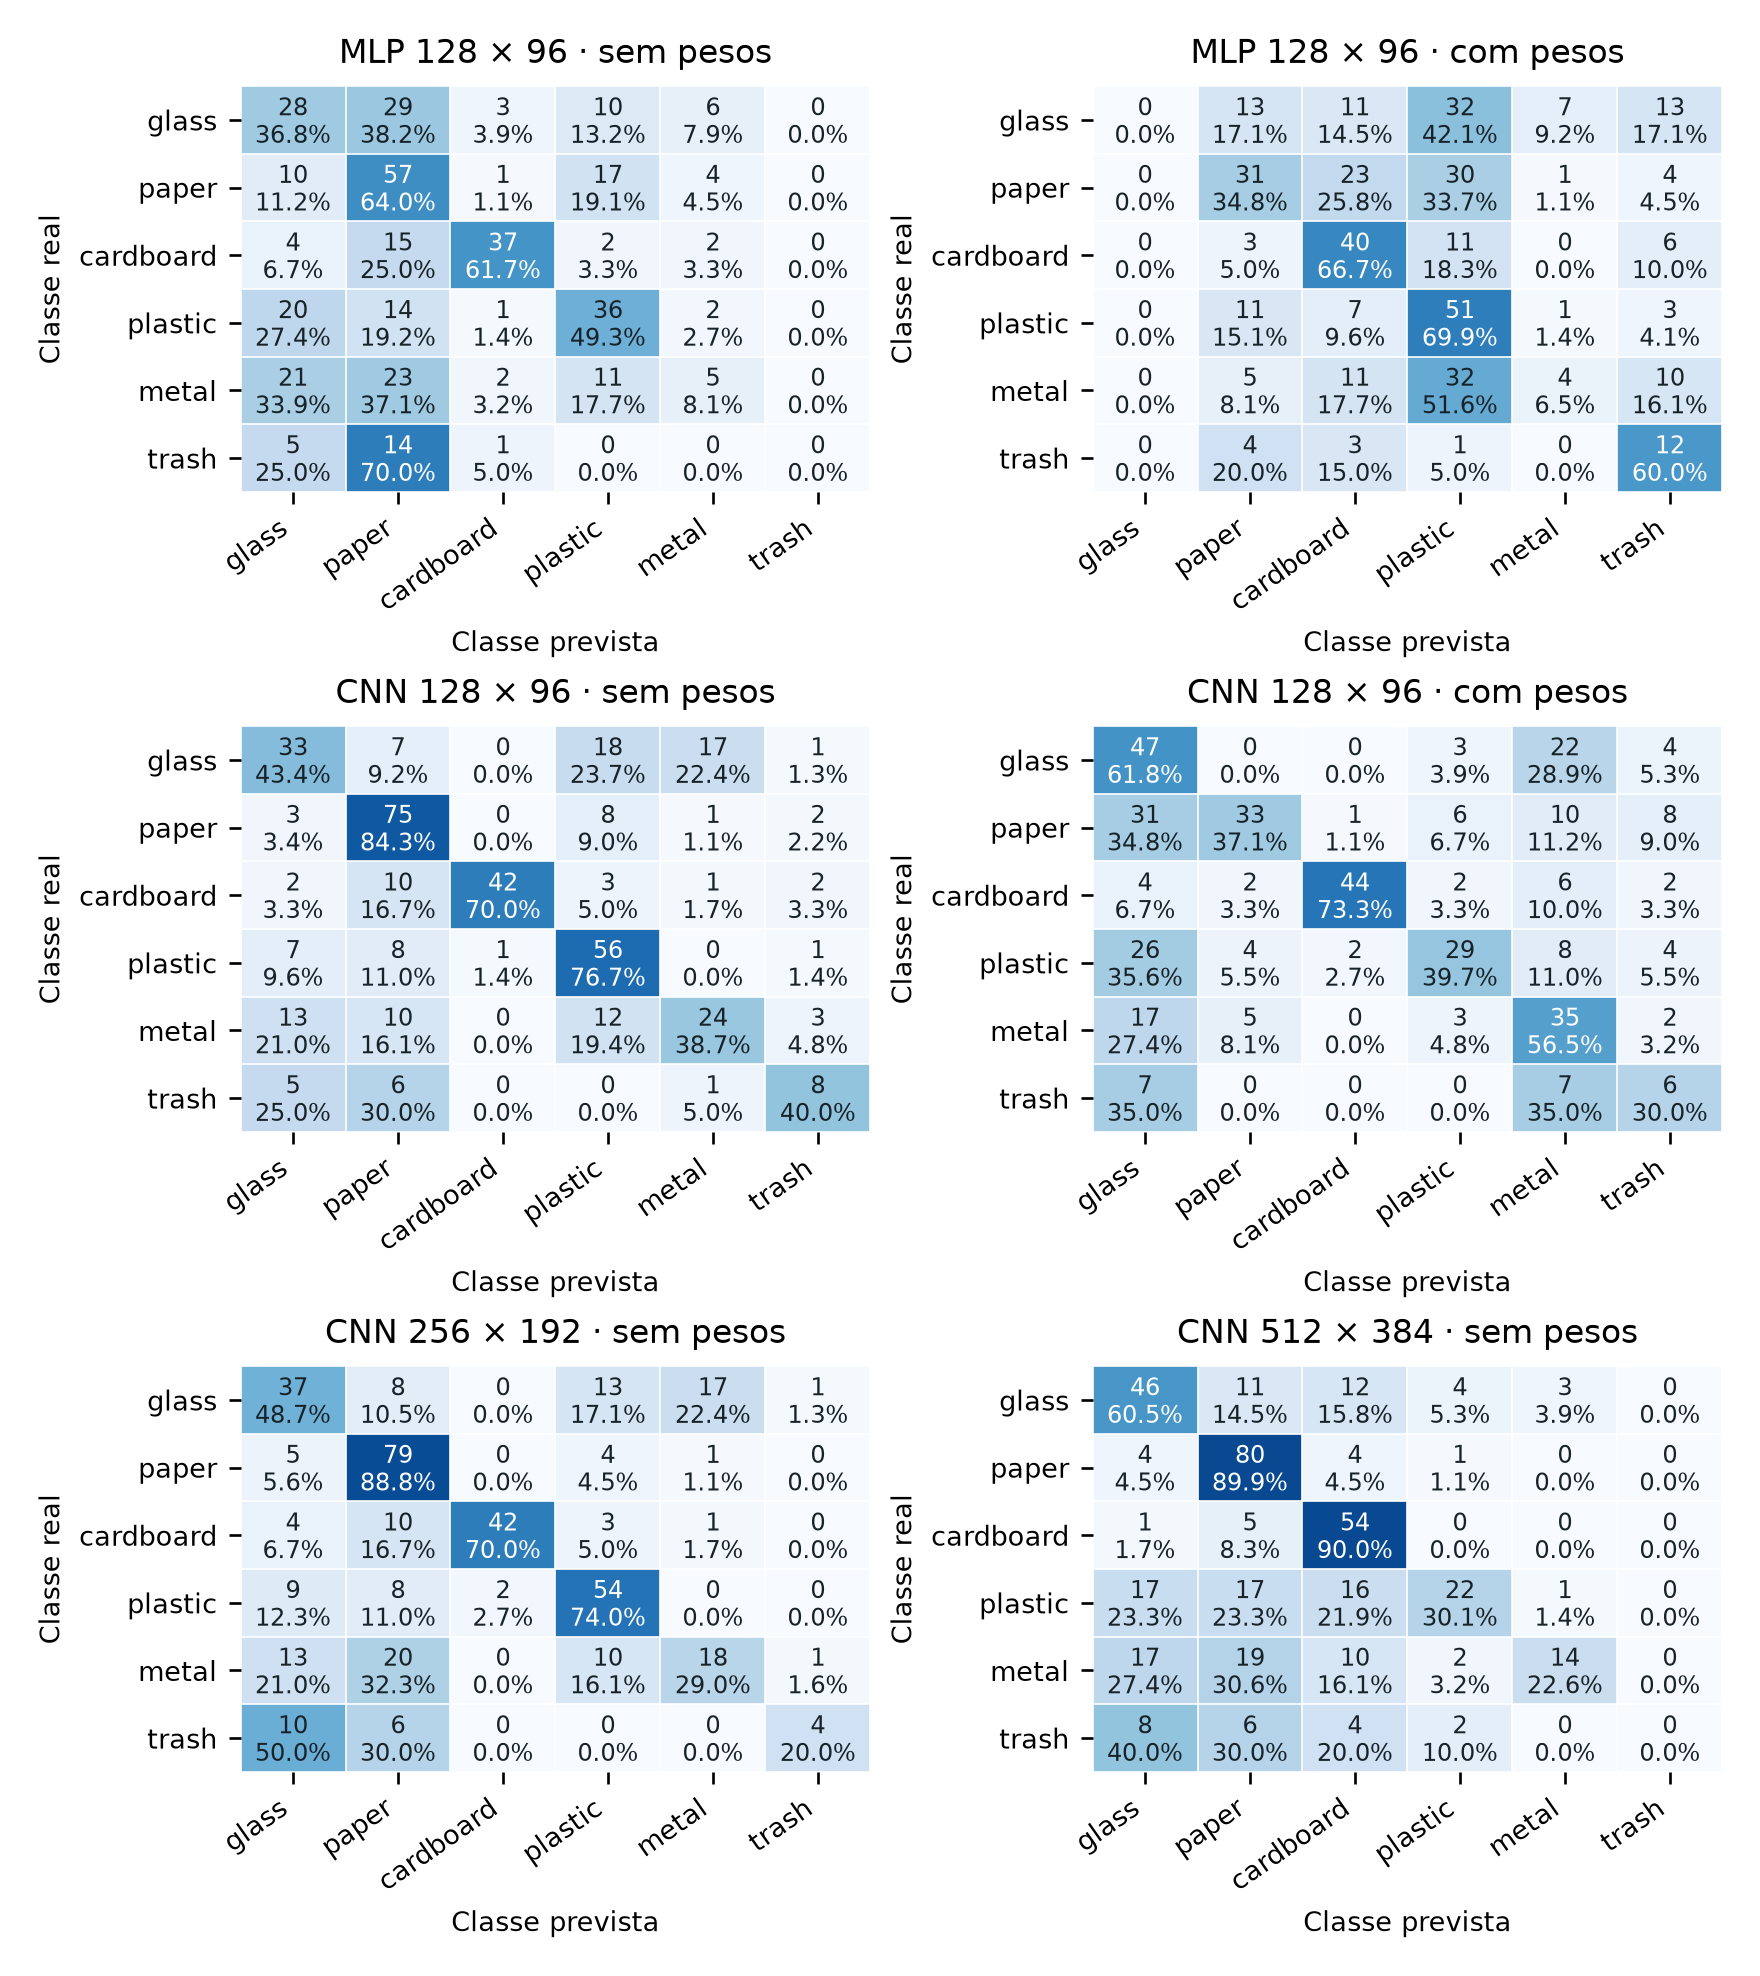

In [8]:
display(Image(filename=str(ROOT / "artifacts/figures/confusion_matrices.png")))


## Arquitetura e pesos de classe

As diferenças abaixo são descritivas para a divisão e a semente registradas. Não são testes de significância nem estimativas de variabilidade entre sementes. Os pares ponderado/não ponderado preservam a configuração de sua arquitetura e alteram os pesos da perda. Entre MLP e CNN também mudam taxa selecionada, estrutura, número de parâmetros e vieses de representação; a conclusão se restringe às implementações executadas.


In [9]:
architecture_rows = []
for weighted, mlp, cnn in [(False,"mlp_128","cnn_128"),(True,"mlp_128_weighted","cnn_128_weighted")]:
    architecture_rows.append({"pesos": weighted, "Δacc_teste_CNN−MLP_pp":100*(summary.loc[cnn,"test_accuracy"]-summary.loc[mlp,"test_accuracy"]), "ΔF1_macro_teste_CNN−MLP_pp":100*(summary.loc[cnn,"test_macro_f1"]-summary.loc[mlp,"test_macro_f1"]), "ΔF1_macro_val_CNN−MLP_pp":100*(summary.loc[cnn,"val_macro_f1"]-summary.loc[mlp,"val_macro_f1"])})
display(pd.DataFrame(architecture_rows))
weight_rows = []
for baseline, weighted in [("mlp_128","mlp_128_weighted"),("cnn_128","cnn_128_weighted")]:
    a = classwise[classwise.run_id == baseline].set_index("class_name")
    b = classwise[classwise.run_id == weighted].set_index("class_name")
    for c in CLASSES:
        weight_rows.append({"arquitetura": baseline.split("_")[0].upper(), "classe": c, "Δprecisão_pp":100*(b.loc[c,"precision"]-a.loc[c,"precision"]), "Δrecall_pp":100*(b.loc[c,"recall"]-a.loc[c,"recall"]), "ΔF1_pp":100*(b.loc[c,"f1"]-a.loc[c,"f1"])})
    delta_f1 = 100*(summary.loc[weighted,"test_macro_f1"]-summary.loc[baseline,"test_macro_f1"])
    delta_trash = 100*(b.loc["trash","f1"]-a.loc["trash","f1"])
    display(Markdown(f"**{baseline.split('_')[0].upper()}:** os pesos alteraram F1 macro de teste em **{delta_f1:+.2f} pontos percentuais** e F1 de `trash` em **{delta_trash:+.2f} pontos percentuais**. As compensações por classe aparecem na tabela."))
display(pd.DataFrame(weight_rows))


,pesos,Δacc_teste_CNN−MLP_pp,ΔF1_macro_teste_CNN−MLP_pp,ΔF1_macro_val_CNN−MLP_pp
0,False,19.7368,24.0036,25.0488
1,True,14.7368,19.6913,28.5671


**MLP:** os pesos alteraram F1 macro de teste em **-5.15 pontos percentuais** e F1 de `trash` em **+35.29 pontos percentuais**. As compensações por classe aparecem na tabela.

**CNN:** os pesos alteraram F1 macro de teste em **-9.47 pontos percentuais** e F1 de `trash` em **-17.16 pontos percentuais**. As compensações por classe aparecem na tabela.

,arquitetura,classe,Δprecisão_pp,Δrecall_pp,ΔF1_pp
0,MLP,glass,-31.8182,-36.8421,-34.1463
1,MLP,paper,8.7687,-29.2135,-7.5593
2,MLP,cardboard,-40.1170,5.0000,-18.8633
3,MLP,plastic,-14.8843,20.5479,-3.9743
4,MLP,metal,4.4534,-1.6129,-1.6790
5,MLP,trash,25.0000,60.0000,35.2941
6,CNN,glass,-16.7749,18.4211,-2.2897
7,CNN,paper,10.3448,-47.1910,-23.5467
8,CNN,cardboard,-4.0574,3.3333,0.6896
9,CNN,plastic,9.7099,-36.9863,-15.8824


## Resolução: desempenho e custo

As três CNNs sem pesos usam a mesma arquitetura com agregação espacial global e são inicializadas novamente. O tamanho da imagem modifica o custo, embora a quantidade de parâmetros possa permanecer constante. O total de treinamento também depende de quantas épocas o critério de parada executou; por isso, é necessário compará-lo junto com o tempo médio por época.


,image_width,image_height,test_accuracy,test_macro_f1,parameters,epochs_trained,train_seconds,mean_epoch_seconds,peak_rss_mb,batch_size
run_id,,,,,,,,,,
cnn_128,128,96,0.6263,0.5944,24198,17,48.2867,2.8404,572.8516,32
cnn_256,256,192,0.6158,0.5609,24198,17,127.2997,7.4882,969.2344,32
cnn_512,512,384,0.5684,0.4496,24198,18,755.9941,41.9997,2305.3438,32


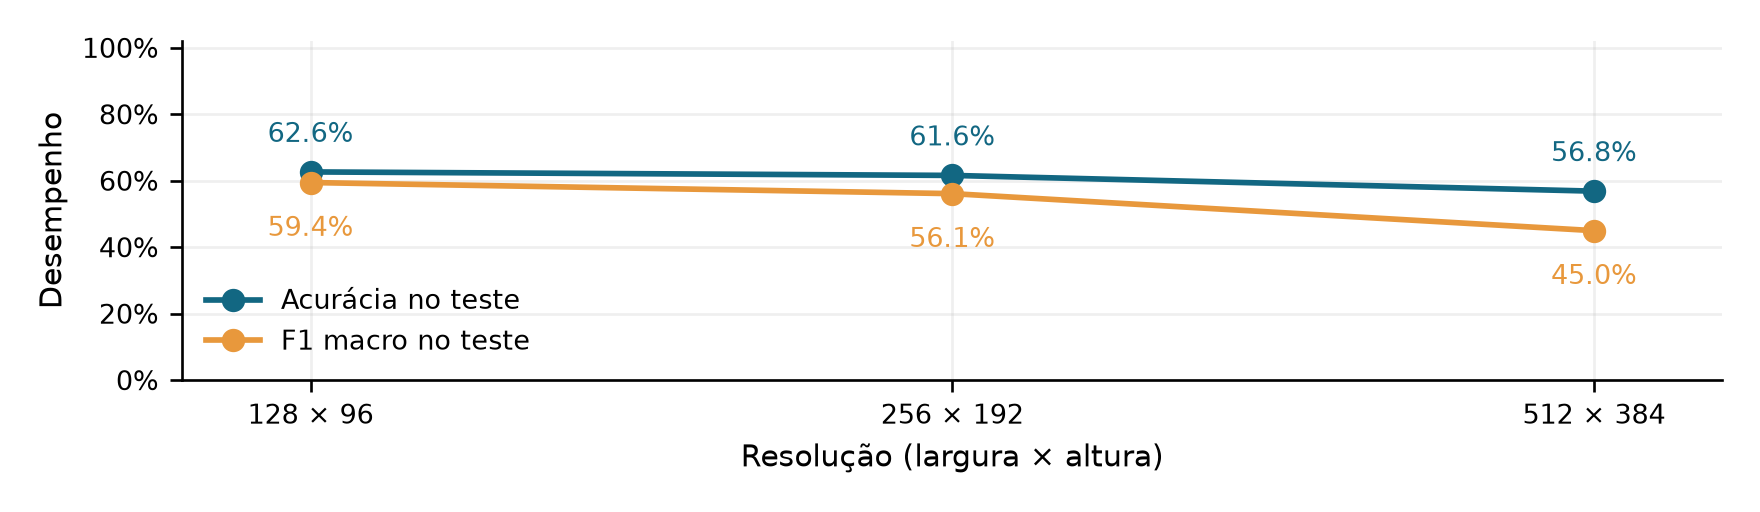

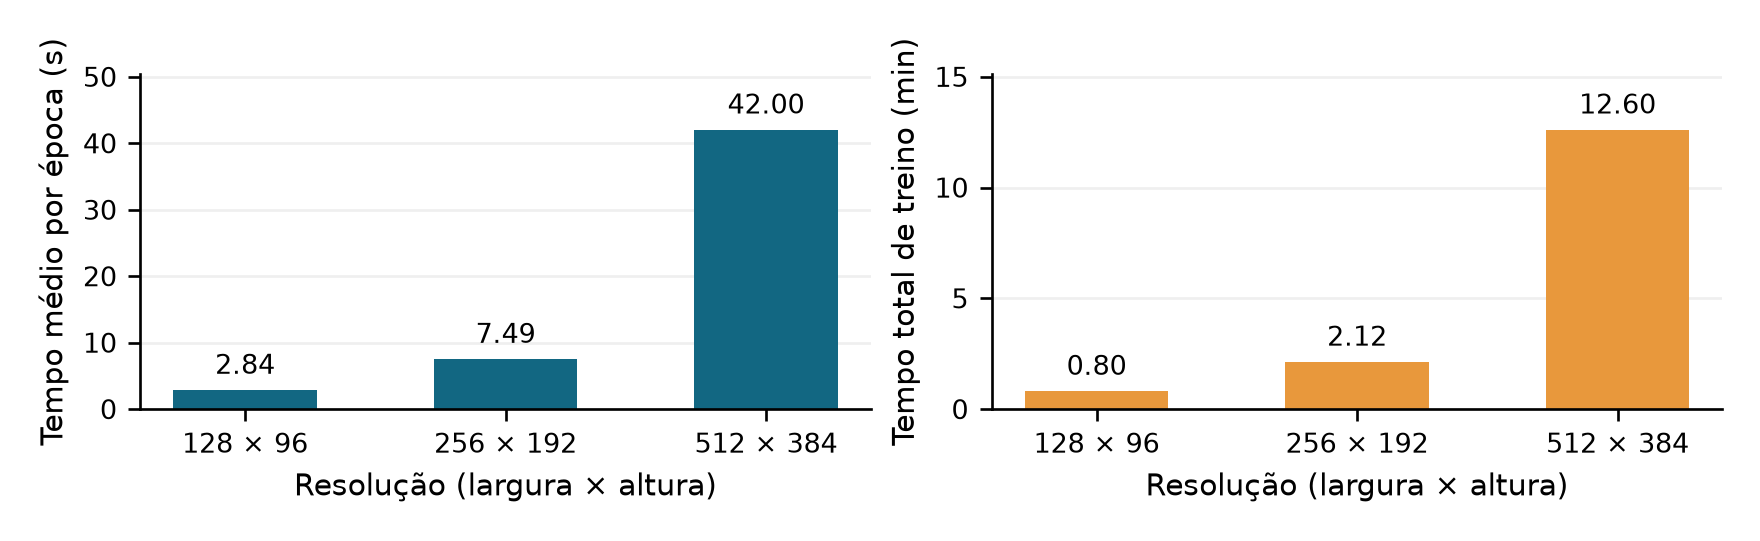

**CNN 256 × 192 · sem pesos:** variação de F1 macro de teste **-3.34 p.p.**; tempo médio por época **2.64×**; tempo total **2.64×**; RSS de pico **1.69×** em relação à CNN 128 × 96 sem pesos.

**CNN 512 × 384 · sem pesos:** variação de F1 macro de teste **-14.48 p.p.**; tempo médio por época **14.79×**; tempo total **15.66×**; RSS de pico **4.02×** em relação à CNN 128 × 96 sem pesos.

In [10]:
resolution_ids = ["cnn_128", "cnn_256", "cnn_512"]
resolution = summary.loc[resolution_ids, ["image_width", "image_height", "test_accuracy", "test_macro_f1", "parameters", "epochs_trained", "train_seconds", "mean_epoch_seconds", "peak_rss_mb", "batch_size"]]
display(resolution)
for name in ["resolution_performance", "resolution_cost"]:
    display(Image(filename=str(ROOT / f"artifacts/figures/{name}.png")))
for run_id in resolution_ids[1:]:
    base, larger = summary.loc["cnn_128"], summary.loc[run_id]
    display(Markdown(f"**{LABELS[run_id]}:** variação de F1 macro de teste **{100*(larger.test_macro_f1-base.test_macro_f1):+.2f} p.p.**; tempo médio por época **{larger.mean_epoch_seconds/base.mean_epoch_seconds:.2f}×**; tempo total **{larger.train_seconds/base.train_seconds:.2f}×**; RSS de pico **{larger.peak_rss_mb/base.peak_rss_mb:.2f}×** em relação à CNN 128 × 96 sem pesos."))


## Erros do modelo escolhido pela validação

São mostrados até seis erros de teste do modelo previamente selecionado, ordenados pela probabilidade da classe prevista (decrescente; empate por caminho). Esse critério torna a escolha auditável e evidencia erros cometidos com maior confiança. A saída softmax é a **probabilidade atribuída pelo modelo**, sem garantia de calibração. O conjunto de erros completo é salvo em CSV.


Modelo: **CNN 128 × 96 · sem pesos**. Erros: **142 em 380 imagens**.

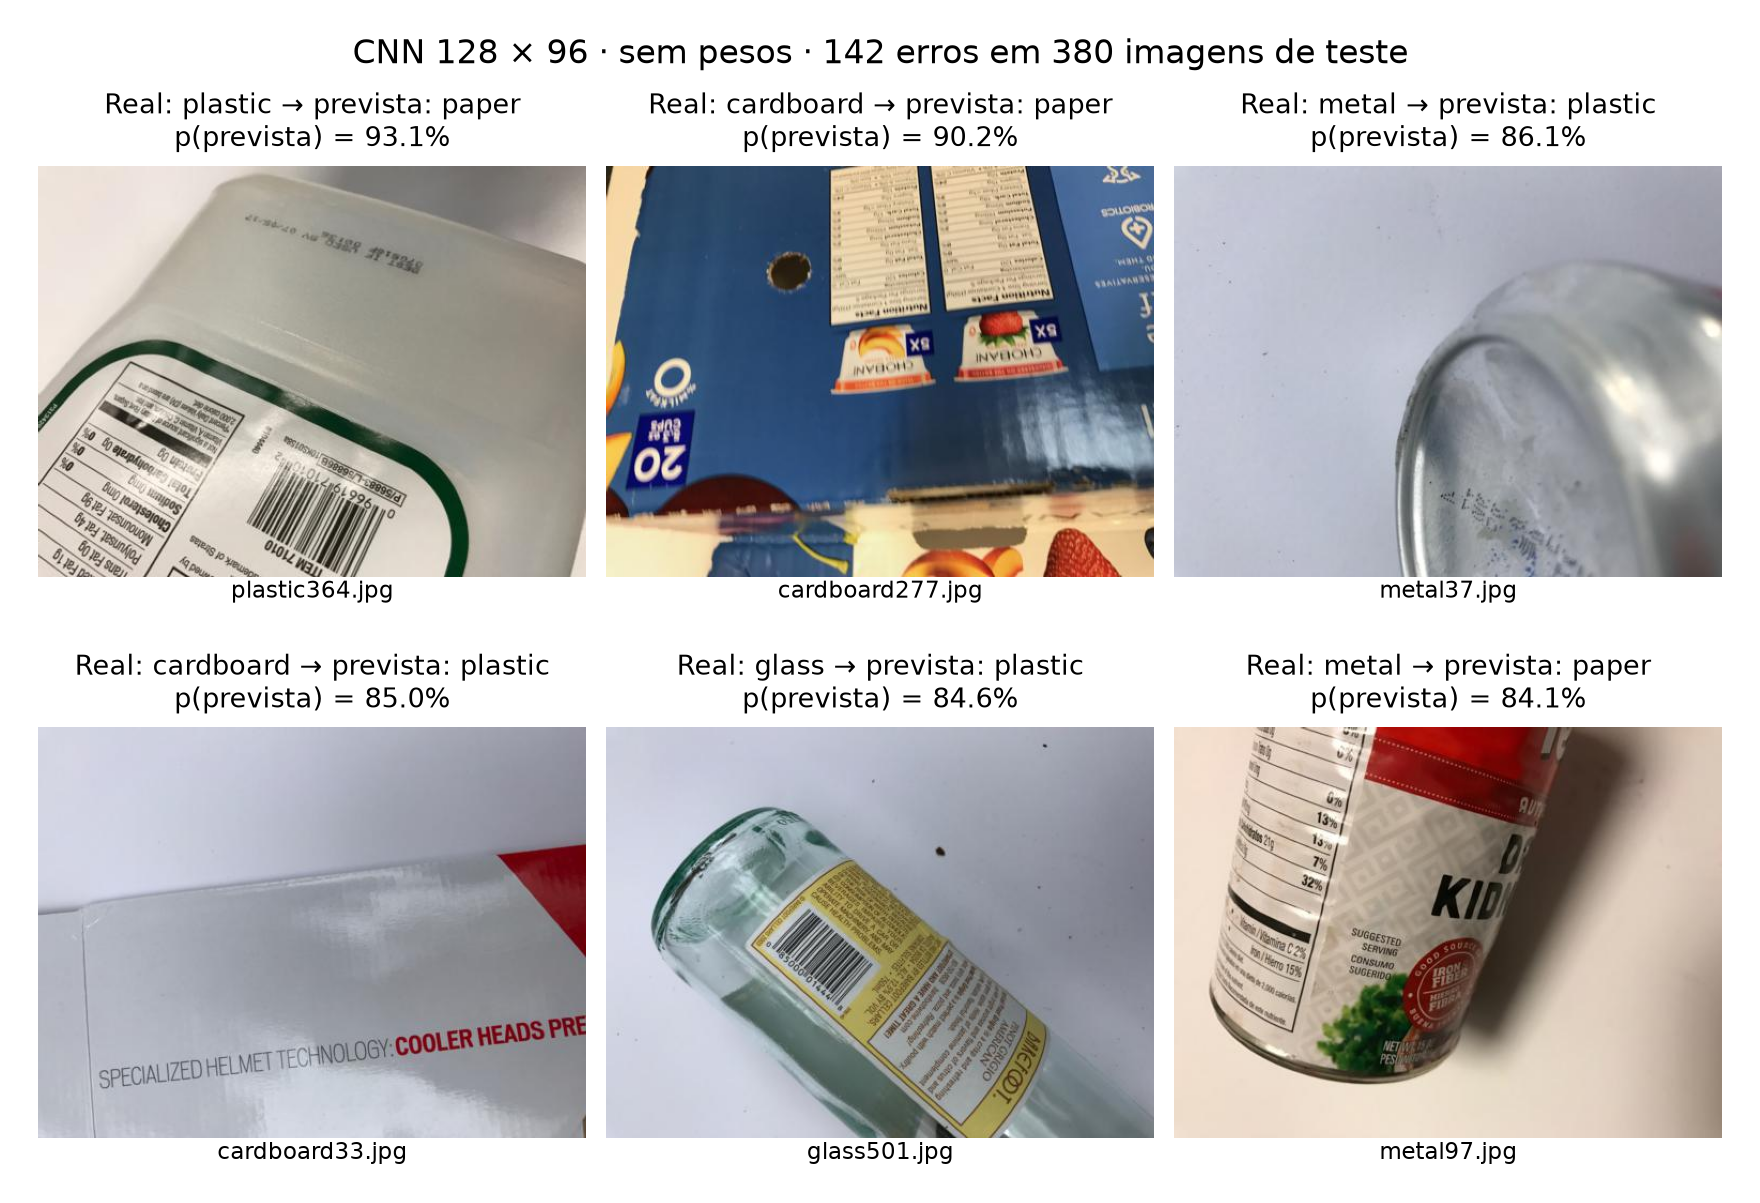

,path,true_class,predicted_class,confidence
325,data/raw/dataset-resized/plastic/plastic364.jpg,plastic,paper,0.9307
31,data/raw/dataset-resized/cardboard/cardboard27...,cardboard,paper,0.9023
179,data/raw/dataset-resized/metal/metal37.jpg,metal,plastic,0.8605
36,data/raw/dataset-resized/cardboard/cardboard33...,cardboard,plastic,0.8505
125,data/raw/dataset-resized/glass/glass501.jpg,glass,plastic,0.8461
197,data/raw/dataset-resized/metal/metal97.jpg,metal,paper,0.8406


,real,prevista,erros,%_da_classe_real
1,glass,plastic,18,23.6842
2,glass,metal,17,22.3684
17,metal,glass,13,20.9677
19,metal,plastic,12,19.3548
9,cardboard,paper,10,16.6667
18,metal,paper,10,16.1290
5,paper,plastic,8,8.9888
14,plastic,paper,8,10.9589
0,glass,paper,7,9.2105
13,plastic,glass,7,9.5890


In [11]:
display(Markdown(f"Modelo: **{LABELS[selected]}**. Erros: **{len(report['errors'])} em {report['metadata']['test_images']} imagens**."))
display(Image(filename=str(ROOT / "artifacts/figures/selected_model_errors.png")))
display(report["errors"][["path", "true_class", "predicted_class", "confidence"]].head(6))
confusions = []
matrix = report["evidence"][selected]["matrix"]
for i, actual in enumerate(CLASSES):
    for j, predicted in enumerate(CLASSES):
        if i != j and matrix[i,j] > 0:
            confusions.append({"real":actual, "prevista":predicted, "erros":int(matrix[i,j]), "%_da_classe_real":100*matrix[i,j]/matrix[i].sum()})
display(pd.DataFrame(confusions).sort_values(["erros","real","prevista"], ascending=[False,True,True]).head(10) if confusions else pd.DataFrame(columns=["real","prevista","erros","%_da_classe_real"]))


### Interpretação e limites

Nos seis erros mostrados, plastic364 e metal97 apresentam rótulos impressos amplos e foram previstos como paper; cardboard277 mostra uma caixa impressa e também foi previsto como paper. Cardboard33 tem superfície clara e lisa; glass501, corpo transparente e etiqueta; ambos foram previstos como plastic. Metal37 aparece em recorte com reflexo suave e também foi confundido com plastic. Sem experimentos explicativos adicionais, essas características são **hipóteses**, não demonstrações de quais sinais a rede utilizou. Fundos controlados e objetos isolados limitam a transferência para fotografias reais, onde aparecem vários materiais, oclusão e iluminação diferente. Conflitos de rótulo preservados na origem acrescentam incerteza supervisionada.

A amostra de `trash` no teste é pequena. Alterar a classificação de poucas imagens pode produzir mudanças expressivas em recall e F1; não se deve generalizar ganhos de uma única execução como efeito universal do balanceamento. Replicações com outras sementes e uma base externa seriam avaliações complementares, mantendo o teste atual fechado para novos ajustes.

O estudo de referência de Yang e Thung apresenta 63% com SVM em seis classes e 22% com CNN em cinco classes, após excluir `trash` da CNN. Classes, divisão, resolução, arquitetura e treinamento diferem deste protocolo. O resultado posterior de aproximadamente 75% citado no README do TrashNet corresponde à continuação no repositório, não ao resultado da CNN publicado no artigo. Essas referências contextualizam o problema, sem estabelecer comparação controlada.


**Leitura das curvas reais:** a MLP sem pesos reduz ambas as perdas, mas estabiliza em acurácia limitada. A CNN melhora no treino, enquanto a validação apresenta picos e deixa de acompanhar a evolução, padrão compatível com sobreajuste e instabilidade. Dropout e BatchNorm impedem interpretar a diferença isolada treino/validação como prova causal.

**Síntese dos efeitos observados:** os pesos elevaram o recall de trash na MLP de 0% para 60%, mas eliminaram previsões glass e reduziram F1 macro. Na CNN, os pesos pioraram trash e F1 macro, apesar de ganhos pequenos de F1 em metal e cardboard. As resoluções 256 e 512 aumentaram custo e reduziram F1 macro frente a 128; neste protocolo, não compensaram. A CNN512 foi retomada após interrupção na época11 com estados de modelo, Adam e geradores preservados.


In [12]:
chosen = summary.loc[selected]
display(Markdown(f"## Síntese numérica\n\nO checkpoint **{LABELS[selected]}**, escolhido por F1 macro de validação **{chosen.val_macro_f1:.4f}**, apresentou acurácia de teste **{chosen.test_accuracy:.4f}** e F1 macro de teste **{chosen.test_macro_f1:.4f}**. Ele foi salvo na época **{int(chosen.best_epoch)}**, após **{int(chosen.epochs_trained)} épocas executadas**. A seleção não usa a ordenação dos resultados de teste. Os ganhos e perdas por classe, o custo e as limitações devem fundamentar a conclusão da equipe."))
print("Figuras:", ROOT / "artifacts/figures")
print("Tabelas:", ROOT / "artifacts/tables")


Figuras: /home/joao/Documents/Codex/2026-10-21/fala-chat-em-resumo-fa-o/work/review/clean/trashnet/artifacts/figures
Tabelas: /home/joao/Documents/Codex/2026-10-21/fala-chat-em-resumo-fa-o/work/review/clean/trashnet/artifacts/tables


## Síntese numérica

O checkpoint **CNN 128 × 96 · sem pesos**, escolhido por F1 macro de validação **0.6333**, apresentou acurácia de teste **0.6263** e F1 macro de teste **0.5944**. Ele foi salvo na época **10**, após **17 épocas executadas**. A seleção não usa a ordenação dos resultados de teste. Os ganhos e perdas por classe, o custo e as limitações devem fundamentar a conclusão da equipe.

## Revisão pela equipe

Antes da entrega, todos os integrantes devem executar os notebooks, conferir as figuras com as previsões e os dados, compreender o código e revisar a interpretação do artigo. Os registros permitem auditar a execução; não substituem a autoria e a responsabilidade acadêmica da equipe. Os resultados de teste já observados não devem orientar ajustes retroativos dos seis experimentos.
